# 🚀 Модуль 2. Урок 1. Реляционные базы данных и фильтрация данных (SELECT, WHERE, NULL)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_02_sql/lesson_01_db_intro_select_filtering.ipynb)

## 📌 Бизнес-контекст и методология
SQL — фундаментальный язык продуктового и бизнес-аналитика. В реляционной СУБД (PostgreSQL, SQLite, BigQuery, Snowflake) данные нормализованы, что исключает дублирование записей.
Навык прецизионной фильтрации через `WHERE` критичен: ошибка в логических предикатах (`AND` vs `OR`, неверная обработка `NULL`) приводит к искажению маркетинговых воронок, задвоению выручки и неверным решениям менеджмента.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

db_path = ensure_dataset("ecommerce.db")
conn = sqlite3.connect(db_path)
print(f"🟢 Подключение к базе данных успешно установлено: {db_path}")

🟢 Подключение к базе данных успешно установлено: course\datasets\ecommerce.db


## 🔍 Разбор механики и демонстрация на реальных данных
Порядок логического выполнения SQL запроса отличается от синтаксического написания:
1. `FROM` & `JOIN` — выбор и связывание таблиц
2. `WHERE` — строчная фильтрация записей (до агрегации!)
3. `SELECT` — выборка и расчет проекций колонок
4. `ORDER BY` — финальная сортировка
5. `LIMIT` — отсечение объема вывода

In [2]:
# Демонстрация: фильтрация премиальных клиентов из ключевых хабов
query_demo = """
SELECT 
    customer_id,
    first_name,
    city,
    acquisition_channel,
    device,
    registration_date
FROM customers
WHERE city IN ('Moscow', 'Saint Petersburg')
  AND registration_date >= '2025-06-01'
  AND acquisition_channel != 'Referral'
ORDER BY registration_date DESC
LIMIT 8;
"""
df_demo = pd.read_sql_query(query_demo, conn)
display(df_demo)

,customer_id,first_name,city,acquisition_channel,device,registration_date
0,679,User_679,Moscow,Email Newsletter,Mobile Android,2026-05-15
1,66,User_66,Moscow,Paid Ads,Mobile iOS,2026-05-12
2,1127,User_1127,Moscow,Paid Ads,Desktop Web,2026-05-08
3,708,User_708,Saint Petersburg,Email Newsletter,Desktop Web,2026-05-05
4,829,User_829,Moscow,Paid Ads,Mobile iOS,2026-05-05
5,431,User_431,Saint Petersburg,Direct,Mobile Android,2026-05-04
6,283,User_283,Moscow,Direct,Mobile Android,2026-05-02
7,394,User_394,Saint Petersburg,Social Media,Mobile iOS,2026-05-02


## 📊 Визуализация бизнес-кейса: Структура каналов привлечения по устройствам
Оценим распределение аудитории по каналам привлечения (`acquisition_channel`) в разрезе платформ (`device`). Это позволяет CMO оптимизировать сплит рекламного бюджета.

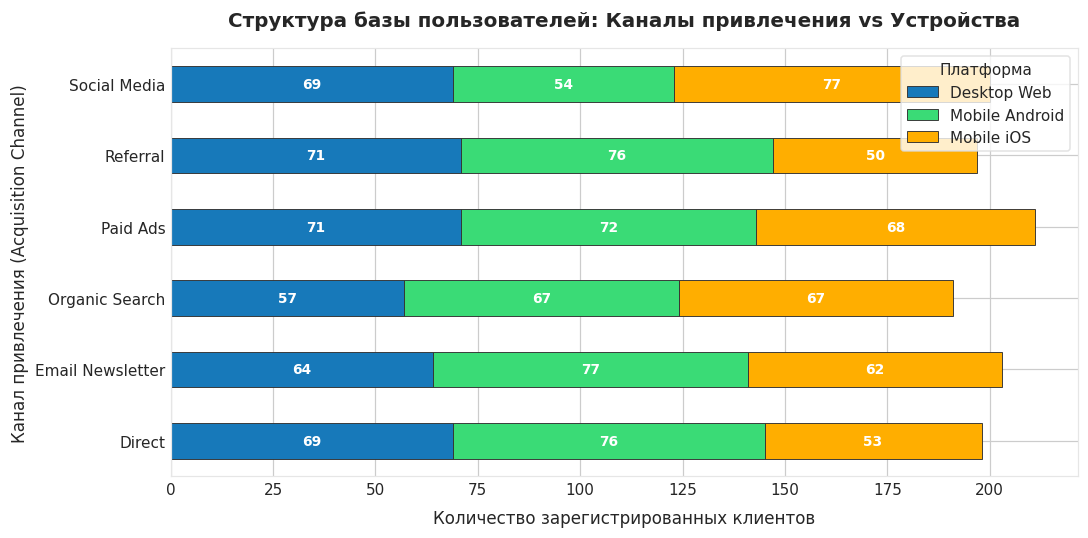

In [3]:
# SQL запрос: кросс-таблица каналов и устройств
query_channels = """
SELECT 
    acquisition_channel,
    device,
    COUNT(*) as user_count
FROM customers
GROUP BY acquisition_channel, device;
"""
df_channels = pd.read_sql_query(query_channels, conn)
pivot_ch = df_channels.pivot(index='acquisition_channel', columns='device', values='user_count').fillna(0)

# Построение визуализации в стиле Foundation
fig, ax = plt.subplots(figsize=(10, 5), dpi=110)
colors = [PRIMARY, SUCCESS, WARNING]

pivot_ch.plot(kind='barh', stacked=True, color=colors, ax=ax, edgecolor='#333333', linewidth=0.6)

ax.set_title("Структура базы пользователей: Каналы привлечения vs Устройства", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Количество зарегистрированных клиентов", fontsize=11, labelpad=8)
ax.set_ylabel("Канал привлечения (Acquisition Channel)", fontsize=11)
ax.legend(title="Платформа", frameon=True, facecolor='#ffffff', edgecolor='#dcdcdc')

# Подписи долей прямо внутри баров
for c in ax.containers:
    labels = [f"{int(v)}" if v > 15 else "" for v in c.datavalues]
    ax.bar_label(c, labels=labels, label_type='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск завершенных заказов через Apple/Mir Pay
Найдите все завершенные заказы со статусом `Completed` и методом оплаты, содержащим `Apple Pay` или `Mir Pay`. Отберите первые 10 строк.

In [4]:
### ВАШ КОД ЗДЕСЬ
query_pay = """
SELECT 
    order_id,
    customer_id,
    order_date,
    status,
    payment_method
FROM orders
WHERE status = 'Completed'
  AND (payment_method LIKE '%Apple Pay%' OR payment_method LIKE '%Mir Pay%')
LIMIT 10;
"""

df_pay = pd.read_sql_query(query_pay, conn)
print("Найдено записей:", len(df_pay))
display(df_pay.head(5))

assert not df_pay.empty, "Заказы должны быть найдены"
assert (df_pay['status'] == 'Completed').all(), "Статус должен быть Completed"
print("✅ Тест успешно пройден: фильтрация отработала безошибочно!")

Найдено записей: 10


,order_id,customer_id,order_date,status,payment_method
0,10001,1,2026-01-28 00:00:00,Completed,Apple Pay / Mir Pay
1,10008,4,2025-09-03 00:00:00,Completed,Apple Pay / Mir Pay
2,10018,9,2025-09-10 00:00:00,Completed,Apple Pay / Mir Pay
3,10021,10,2026-05-16 00:00:00,Completed,Apple Pay / Mir Pay
4,10027,13,2025-09-27 00:00:00,Completed,Apple Pay / Mir Pay


✅ Тест успешно пройден: фильтрация отработала безошибочно!


### 💡 Трехзначная логика SQL и работа с NULL
В реляционных базах используется трёхзначная логика (`TRUE`, `FALSE`, `UNKNOWN`). Любая операция сравнения с `NULL` (например, `status = NULL` или `status != NULL`) возвращает `UNKNOWN`, из-за чего строка отсекается предикатом `WHERE`.
Всегда используйте синтаксис `IS NULL` или `IS NOT NULL`, либо функцию `COALESCE(column, default_value)`.